In [7]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [8]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)


lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [11]:
XCT = np.linspace(0, NTOT*AX, 51)
YCT = M/2*AY

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.Hamiltonian_simplified(XCT[i], YCT)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('E_vs_xct_V1.npy', Ep)

[-0.7135342  -0.38428592  0.38428592  0.7135342 ]
[-0.71353421 -0.38428591  0.38428591  0.71353421]
[-0.71353421 -0.3842859   0.3842859   0.71353421]
[-0.71353422 -0.38428589  0.38428589  0.71353422]
[-0.71353422 -0.38428587  0.38428587  0.71353422]
[-0.71353423 -0.38428586  0.38428586  0.71353423]
[-0.71353424 -0.38428584  0.38428584  0.71353424]
[-0.71353425 -0.38428581  0.38428581  0.71353425]
[-0.71353426 -0.38428578  0.38428578  0.71353426]
[-0.71353428 -0.38428574  0.38428574  0.71353428]
[-0.7135343  -0.38428569  0.38428569  0.7135343 ]
[-0.71353433 -0.38428563  0.38428563  0.71353433]
[-0.71353437 -0.38428554  0.38428554  0.71353437]
[-0.71353443 -0.38428542  0.38428542  0.71353443]
[-0.7135345  -0.38428526  0.38428526  0.7135345 ]
[-0.71353461 -0.38428502  0.38428502  0.71353461]
[-0.71353478 -0.38428466  0.38428466  0.71353478]
[-0.71353504 -0.38428409  0.38428409  0.71353504]
[-0.71353548 -0.38428315  0.38428315  0.71353548]
[-0.71353627 -0.38428145  0.38428145  0.71353627]


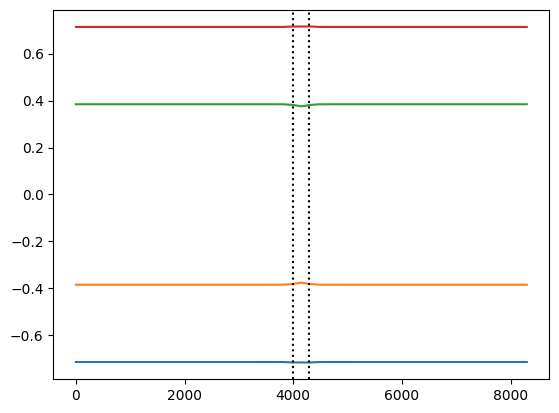

In [15]:
plt.plot(XCT, Ep)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

In [17]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 51)
YCT = M/2*AY

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.Hamiltonian_simplified(XCT[i], YCT)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('E_vs_xct_V2.npy', Ep)

[-0.71431524 -0.38313288  0.38313288  0.71431524]
[-0.71447793 -0.38291489  0.38291489  0.71447793]
[-0.71467988 -0.38264662  0.38264662  0.71467988]
[-0.71492773 -0.38231896  0.38231896  0.71492773]
[-0.71522534 -0.38192513  0.38192513  0.71522534]
[-0.7155704  -0.38146401  0.38146401  0.7155704 ]
[-0.71595091 -0.38094365  0.38094365  0.71595091]
[-0.71634416 -0.38038228  0.38038228  0.71634416]
[-0.71672041 -0.3798048   0.3798048   0.71672041]
[-0.71704998 -0.37923626  0.37923626  0.71704998]
[-0.71730983 -0.37869614  0.37869614  0.71730983]
[-0.71748631 -0.37819647  0.37819647  0.71748631]
[-0.71757464 -0.37774294  0.37774294  0.71757464]
[-0.71757698 -0.37733706  0.37733706  0.71757698]
[-0.71750046 -0.37697801  0.37697801  0.71750046]
[-0.71735575 -0.37666374  0.37666374  0.71735575]
[-0.71715598 -0.37639162  0.37639162  0.71715598]
[-0.71691592 -0.37615874  0.37615874  0.71691592]
[-0.71665125 -0.37596207  0.37596207  0.71665125]
[-0.71637796 -0.37579859  0.37579859  0.71637796]


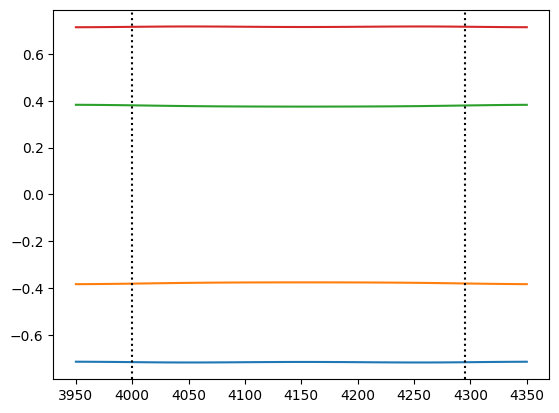

In [18]:
plt.plot(XCT, Ep)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

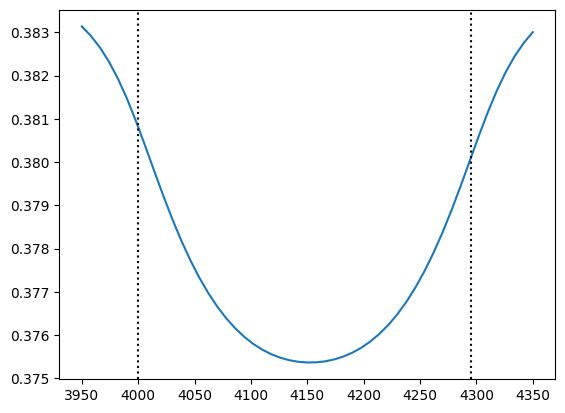

In [19]:
plt.plot(XCT, Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

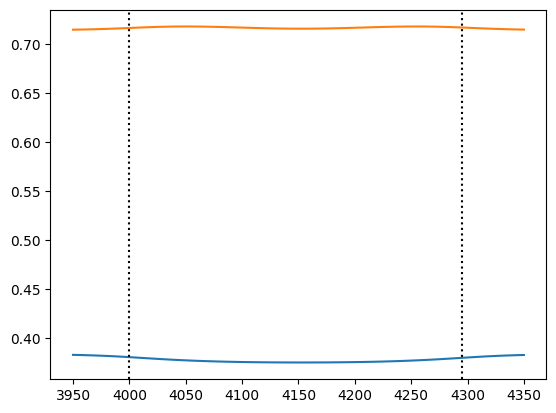

In [20]:
plt.plot(XCT, Ep[:, K_NUM//2:K_NUM])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

In [22]:
XCT = (NSC+NSM/2)*AX
YCT = np.linspace(-M*AY,2*M*AY, 51 )

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.Hamiltonian_simplified(XCT, YCT[i])

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('E_vs_yct_V1.npy', Ep)

[-0.71355389 -0.38424096  0.38424096  0.71355389]
[-0.71355631 -0.38423528  0.38423528  0.71355631]
[-0.71355915 -0.38422861  0.38422861  0.71355915]
[-0.71356249 -0.38422072  0.38422072  0.71356249]
[-0.71356644 -0.38421132  0.38421132  0.71356644]
[-0.71357114 -0.38420005  0.38420005  0.71357114]
[-0.71357679 -0.38418641  0.38418641  0.71357679]
[-0.71358361 -0.38416975  0.38416975  0.71358361]
[-0.71359194 -0.38414918  0.38414918  0.71359194]
[-0.71360219 -0.38412353  0.38412353  0.71360219]
[-0.71361493 -0.38409112  0.38409112  0.71361493]
[-0.71363091 -0.38404962  0.38404962  0.71363091]
[-0.71365121 -0.38399563  0.38399563  0.71365121]
[-0.71367726 -0.38392419  0.38392419  0.71367726]
[-0.7137111  -0.38382782  0.38382782  0.7137111 ]
[-0.71375554 -0.38369499  0.38369499  0.71375554]
[-0.71381454 -0.38350758  0.38350758  0.71381454]
[-0.71389341 -0.38323708  0.38323708  0.71389341]
[-0.71399901 -0.38283966  0.38283966  0.71399901]
[-0.71413908 -0.38225346  0.38225346  0.71413908]


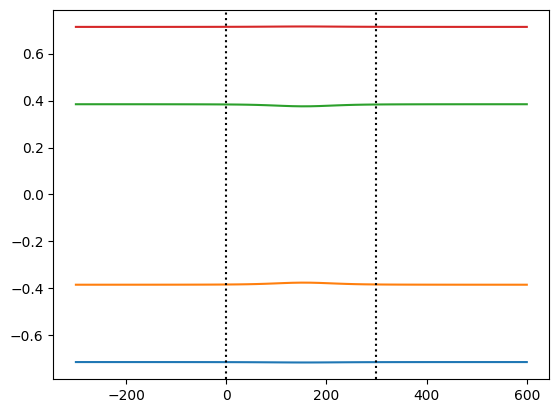

In [26]:
plt.plot(YCT, Ep)
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

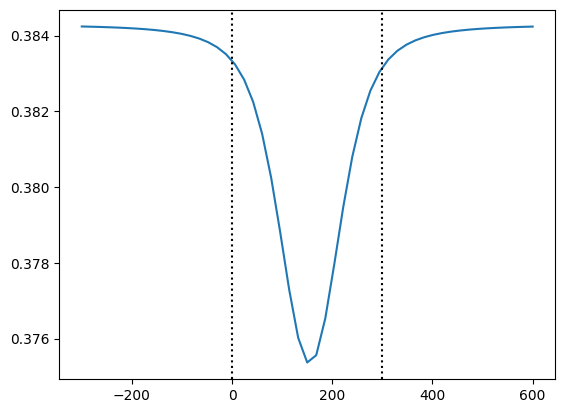

In [29]:
plt.plot(YCT, Ep[:, K_NUM//2])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

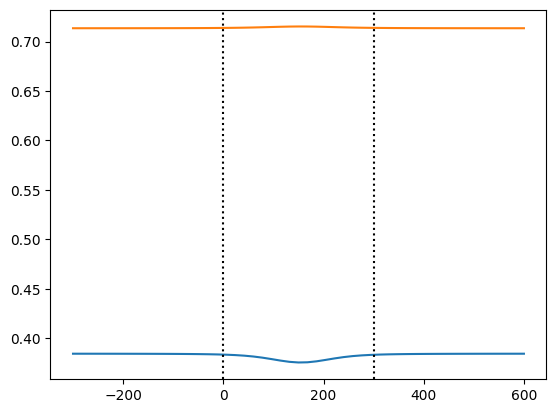

In [31]:
plt.plot(YCT, Ep[:, K_NUM//2:K_NUM])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

In [32]:
XCT = (NSC+NSM/2)*AX
YCT = np.linspace(0,M*AY, 51 )

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.Hamiltonian_simplified(XCT, YCT[i])

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('E_vs_yct_V2.npy', Ep)

[-0.71386452 -0.38333882  0.38333882  0.71386452]
[-0.71389341 -0.38323708  0.38323708  0.71389341]
[-0.71392527 -0.3831214   0.3831214   0.71392527]
[-0.71396037 -0.3829897   0.3829897   0.71396037]
[-0.71399901 -0.38283966  0.38283966  0.71399901]
[-0.71404149 -0.38266876  0.38266876  0.71404149]
[-0.7140881  -0.38247429  0.38247429  0.7140881 ]
[-0.71413908 -0.38225346  0.38225346  0.71413908]
[-0.71419464 -0.38200348  0.38200348  0.71419464]
[-0.71425493 -0.38172182  0.38172182  0.71425493]
[-0.71431998 -0.38140634  0.38140634  0.71431998]
[-0.7143897  -0.38105561  0.38105561  0.7143897 ]
[-0.71446383 -0.38066926  0.38066926  0.71446383]
[-0.71454192 -0.38024826  0.38024826  0.71454192]
[-0.71462329 -0.37979529  0.37979529  0.71462329]
[-0.71470701 -0.37931504  0.37931504  0.71470701]
[-0.71479192 -0.37881435  0.37881435  0.71479192]
[-0.7148766  -0.37830236  0.37830236  0.7148766 ]
[-0.71495939 -0.3777903   0.3777903   0.71495939]
[-0.71503849 -0.37729124  0.37729124  0.71503849]


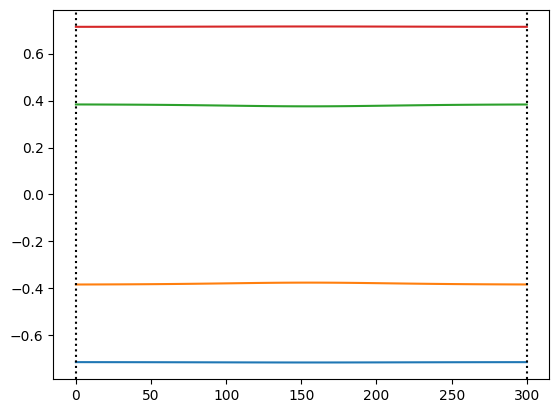

In [33]:
plt.plot(YCT, Ep)
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

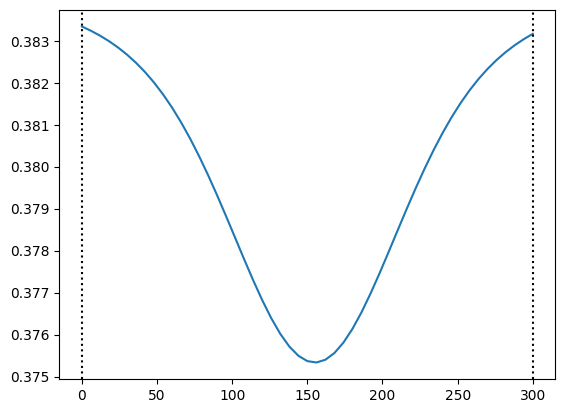

In [34]:
plt.plot(YCT, Ep[:, K_NUM//2])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

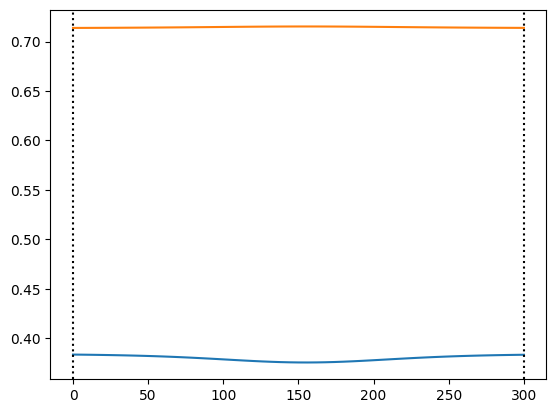

In [35]:
plt.plot(YCT, Ep[:, K_NUM//2:K_NUM])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')